# CNN sur Fashion-MNIST

In [4]:
# Colab : monte le Drive et se place dans le repo
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/MyDrive/early-dropout
!git pull

Mounted at /content/drive
/content/drive/MyDrive/early-dropout
remote: Enumerating objects: 18, done.
remote: Counting objects: 100% (15/15), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 10 (delta 7), reused 8 (delta 5), pack-reused 0 (from 0)
Unpacking objects: 100% (10/10), 1.72 KiB | 7.00 KiB/s, done.
From https://github.com/Felix-prjcts/early-dropout-study
   0813ca2..e0efe53  master     -> origin/master
Updating 0813ca2..e0efe53
Fast-forward
 __pycache__/train.cpython-311.pyc | Bin 4515 -> 4647 bytes
 train.py                          |  14 ++++++++++----
 2 files changed, 10 insertions(+), 4 deletions(-)


In [1]:
import os, glob, time, importlib
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision import datasets

import config, models, train
importlib.reload(config); importlib.reload(models); importlib.reload(train)
from config import BATCH, P, EARLY_GRID
from models import cnn
from train import entrainer

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cpu


In [2]:
tr = datasets.FashionMNIST("./data", train=True, download=True)
te = datasets.FashionMNIST("./data", train=False, download=True)
Xtr = tr.data.float().unsqueeze(1) / 255      # (N, 1, 28, 28) : on garde la forme d'image pour le CNN
Xte = te.data.float().unsqueeze(1) / 255
ytr, yte = tr.targets, te.targets

# même split de validation que pour le MLP
perm = torch.randperm(len(Xtr), generator=torch.Generator().manual_seed(0))
Xva, yva = Xtr[perm[:10000]], ytr[perm[:10000]]
Xtr, ytr = Xtr[perm[10000:]], ytr[perm[10000:]]

# normalisation avec les stats du train uniquement
mu, sd = Xtr.mean(), Xtr.std()
Xtr, Xva, Xte = (Xtr - mu) / sd, (Xva - mu) / sd, (Xte - mu) / sd

data = dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte)
data = {k: v.to(device) for k, v in data.items()}       # tout sur le GPU
print(Xtr.shape, Xva.shape, Xte.shape)

torch.Size([50000, 1, 28, 28]) torch.Size([10000, 1, 28, 28]) torch.Size([10000, 1, 28, 28])


In [3]:
CADRE = "cnn_fmnist"
OUT = "resultats"

## Calibration : trouver un régime de sous-apprentissage
On compare sans dropout et dropout classique. delta = acc val (dropout classique) - acc val (sans dropout) : si delta < 0 le modèle sous-apprend, c'est ce qu'on cherche.

In [11]:
CALIB_LARGEURS = [4, 8, 16]
CALIB_EPOCHS = [10, 20, 50]
CALIB_GRID = [0, 1]          # 0 = sans dropout, 1 = dropout classique
CALIB_SEEDS = [0, 1]

for L in CALIB_LARGEURS:
    for E in CALIB_EPOCHS:
        for frac in CALIB_GRID:
            for seed in CALIB_SEEDS:
                fichier = f"{OUT}/{CADRE}_w{L}_e{E}_frac{frac}_s{seed}.csv"
                if os.path.exists(fichier):
                    continue
                torch.manual_seed(seed)
                model, opt = cnn(1, 10, largeur=L)
                model.to(device)
                hist = entrainer(model, opt, data, E, t_early=round(frac * E), p=P, batch=BATCH)
                hist.assign(cadre=CADRE, width=L, epochs=E, frac=frac, seed=seed).to_csv(fichier, index=False)

Epoch 1/50

KeyboardInterrupt: 

In [5]:
cal = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w*_e*_frac*_s*.csv"))
cal = cal[cal.width.isin(CALIB_LARGEURS) & cal.epochs.isin(CALIB_EPOCHS) & cal.frac.isin(CALIB_GRID)]

# valeur finale = moyenne des 5 dernières epochs de chaque run
fin = (cal[cal.epoch >= cal.epochs - 5]
       .groupby(["width", "epochs", "frac", "seed"])[["train_loss", "val_loss", "val_acc"]].mean()
       .reset_index())

t = fin.pivot_table(index=["width", "epochs", "seed"], columns="frac", values="val_acc")
t["delta"] = (t[1] - t[0]) * 100                         # dropout classique - sans dropout, en points
tab = t.groupby(["width", "epochs"]).agg(
    acc_sans_dropout=(0, "mean"),
    delta_moy=("delta", "mean"),
    delta_min=("delta", "min"),
    delta_max=("delta", "max"),
)
tab["sous_apprentissage"] = tab.delta_max <= -0.5         # toutes les seeds perdent au moins 0.5 pt
tab.round(3)

acc_sans_dropout  delta_moy  delta_min  delta_max  \
width epochs                                                      
4     10                 0.804     -1.436     -2.030     -0.842   
      20                 0.840     -0.645     -1.360      0.070   
8     10                 0.860     -0.966     -1.566     -0.366   
      20                 0.889     -0.488     -0.960     -0.136   
16    10                 0.887     -0.003     -0.278      0.272   
      20                 0.911      0.021     -0.190      0.232   

              sous_apprentissage  
width epochs                      
4     10                    True  
      20                   False  
8     10                   False  
      20                   False  
16    10                   False  
      20                   False

On retient 20 epochs et 8 de largeur car ce modele est en sous_apprentissage avec une accuracy correcte. Ensuite on lance la grille complète comme pour le MLP.

In [6]:
LARGEUR = 8      
EPOCHS = 20      
SEEDS = [0, 1, 2, 3, 4]

for frac in EARLY_GRID:
    for seed in SEEDS:
        fichier = f"{OUT}/{CADRE}_w{LARGEUR}_e{EPOCHS}_frac{frac}_s{seed}.csv"
        if os.path.exists(fichier):
            continue
        torch.manual_seed(seed)
        model, opt = cnn(1, 10, largeur=LARGEUR)
        model.to(device)
        hist = entrainer(model, opt, data, EPOCHS, t_early=round(frac * EPOCHS), p=P, batch=BATCH)
        hist.assign(cadre=CADRE, width=LARGEUR, epochs=EPOCHS, frac=frac, seed=seed).to_csv(fichier, index=False)

In [7]:
# gain par rapport à "sans dropout", seed par seed, avec IC à 95 % (Student, 5 seeds)
metriques = ["train_loss", "val_loss", "val_acc", "test_acc"]
fin = {}
for frac in EARLY_GRID:
    fin[frac] = pd.DataFrame(
        [pd.read_csv(f"{OUT}/{CADRE}_w{LARGEUR}_e{EPOCHS}_frac{frac}_s{s}.csv").tail(5)[metriques].mean() for s in SEEDS],
        index=SEEDS)

res = {}
for frac in EARLY_GRID:
    if frac == 0:
        continue
    d = fin[frac] - fin[0]
    d[["val_acc", "test_acc"]] *= 100                     # accuracy en points
    ic = 2.776 * d.std() / len(SEEDS) ** 0.5
    res[frac] = pd.concat([d.mean(), ic.add_prefix("ic_")])
pd.DataFrame(res).T.round(3)

,train_loss,val_loss,val_acc,test_acc,ic_train_loss,ic_val_loss,ic_val_acc,ic_test_acc
0.1,-0.003,-0.002,-0.026,0.096,0.011,0.008,0.189,0.202
0.2,-0.005,-0.002,-0.018,0.206,0.010,0.010,0.154,0.326
0.3,-0.005,-0.003,0.112,0.102,0.011,0.011,0.148,0.402
0.5,0.001,-0.001,-0.147,0.034,0.010,0.008,0.110,0.425
1.0,0.018,0.008,-0.488,-0.341,0.011,0.013,0.372,0.439


In [8]:
EPOCHS_LIST = [20]                 
T95 = {2: 12.71, 3: 4.30, 4: 3.18, 5: 2.78}
ic = lambda x: T95[len(x)] * x.std() / len(x) ** 0.5

comp = []
for E in EPOCHS_LIST:
    d = pd.concat(pd.read_csv(f) for f in glob.glob(f"{OUT}/{CADRE}_w{LARGEUR}_e{E}_frac*_s*.csv"))
    d = d[d.seed.isin(SEEDS) & d.frac.isin(EARLY_GRID)]
    f = (d[d.epoch >= E - 5]
         .groupby(["frac", "seed"])[["train_loss", "val_acc", "test_acc"]].mean()
         .reset_index())
    b = f[f.frac == 0].set_index("seed")
    for col in ["train_loss", "val_acc", "test_acc"]:
        f[f"d_{col}"] = f[col].values - b.loc[f.seed, col].values
    f["epochs"] = E
    comp.append(f)
comp = pd.concat(comp)

tab = comp.groupby(["epochs", "frac"]).agg(
    gain_val=("d_val_acc", lambda x: 100 * x.mean()),
    ic_val=("d_val_acc", lambda x: 100 * ic(x)),
    gain_test=("d_test_acc", lambda x: 100 * x.mean()),
    ic_test=("d_test_acc", lambda x: 100 * ic(x)),
    d_train_loss=("d_train_loss", "mean"),
    ic_train_loss=("d_train_loss", ic),
)
tab.round(3)

gain_val  ic_val  gain_test  ic_test  d_train_loss  ic_train_loss
epochs frac                                                                   
20     0.0      0.000   0.000      0.000    0.000         0.000          0.000
       0.1     -0.026   0.189      0.096    0.202        -0.003          0.011
       0.2     -0.018   0.154      0.206    0.327        -0.005          0.010
       0.3      0.112   0.148      0.102    0.403        -0.005          0.011
       0.5     -0.147   0.111      0.034    0.425         0.001          0.010
       1.0     -0.488   0.373     -0.341    0.439         0.018          0.011

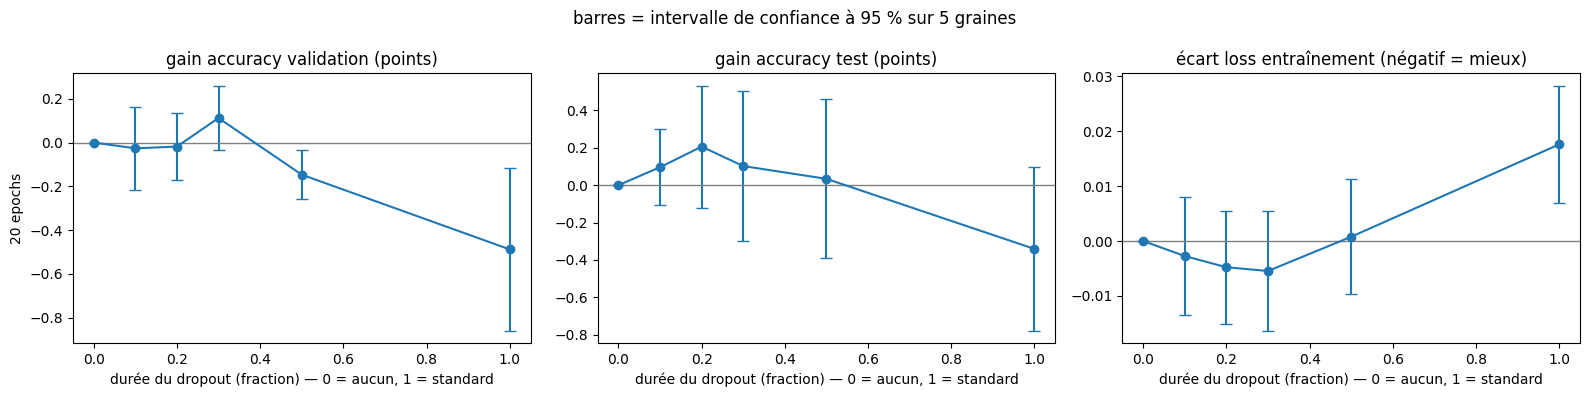

In [9]:
fig, axes = plt.subplots(len(EPOCHS_LIST), 3, figsize=(16, 4 * len(EPOCHS_LIST)), sharey="col", squeeze=False)
for r, E in enumerate(EPOCHS_LIST):
    t = tab.loc[E]
    axes[r, 0].errorbar(t.index, t.gain_val, yerr=t.ic_val, marker="o", capsize=4)
    axes[r, 1].errorbar(t.index, t.gain_test, yerr=t.ic_test, marker="o", capsize=4)
    axes[r, 2].errorbar(t.index, t.d_train_loss, yerr=t.ic_train_loss, marker="o", capsize=4)
    axes[r, 0].set_ylabel(f"{E} epochs")
    for ax in axes[r]:
        ax.axhline(0, color="gray", lw=1)
        ax.set_xlabel("durée du dropout (fraction) — 0 = aucun, 1 = standard")
axes[0, 0].set_title("gain accuracy validation (points)")
axes[0, 1].set_title("gain accuracy test (points)")
axes[0, 2].set_title("écart loss entraînement (négatif = mieux)")
plt.suptitle("barres = intervalle de confiance à 95 % sur 5 graines")
plt.tight_layout(); plt.show()

In [10]:
# from google.colab import drive, userdata
# drive.mount("/content/drive")
# %cd /content/drive/MyDrive/early-dropout

# !git config user.name "Felix-prjcts"
# !git config user.email "TON_ADRESSE_NOREPLY"     # voir plus bas
# !git add cnn_fmnist.ipynb resultats/
# !git commit -m "cnn fmnist : calibration + grille largeur 8, 20 epochs"

# token = userdata.get("GITHUB_TOKEN")              # exactement le nom du secret dans le panneau 🔑
# !git push -q https://{token}@github.com/Felix-prjcts/early-dropout-study.git main 2>&1 | sed "s/{token}/***/g"